# External DNA language models on scATAC-seq, biosample-grouped CV (Comment 3.M5)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

The reviewer asked how LEAF-1 compares with general-purpose DNA language models
on scATAC-seq. This is the scATAC counterpart of `cfdna_dnalm_baselines`
(Supp. Fig. 7), in the same layout and sign convention.

1,000 cells from 10 cell types of the Zhang 2021 atlas (100 cells each,
one-vs-all tasks), 1,000 fragments per cell. Each fragment is embedded by LEAF-1
(central fragment-body window, layer 4) or one of six external DNA LMs; a cell
is the mean of its fragment embeddings. k-mer frequency vectors (k = 3-6) are the
sequence-composition baseline. Every representation is standardized and scored
with the same class-balanced linear SVM (C by inner 3-fold CV) on the same folds.

Primary evaluation is biosample-grouped 5-fold CV with the group assignment of
`scatac_atlas_grouped_cv` (for these cells every group is one GTEx biosample).
Two tasks are not evaluable (their positives sit in too few biosamples) and
Luteal Cell (Ovarian) is evaluable but degenerate (two training positives in one
fold; every model below 0.5), so means are over the remaining seven tasks.
ΔAUC = LEAF-1 − model with paired 95% CIs from 2,000 bootstrap resamples of
biosamples, computed upstream (staged in `scatac_dnalm_paired_delta.csv`).

Panels:
- `scatac_dnalm_delta_auc`:
  a, mean AUC under grouped CV (filled; BCa 95% CI over the 7 tasks, 10,000
  resamples) linked to the same model's cell-level CV mean (open); LEAF-1 first, LEAF-1 over all embedding segments second, then
  the external models in panel b order;
  b, mean ΔAUC (LEAF-1 − model) against the external DNA LMs, grouped CV;
  c, the same against the k-mer baselines. A ΔAUC point is blue when its CI
  excludes 0 in LEAF-1's favour and orange otherwise. Point estimates with CI
  whiskers rather than bars; per-task values are in the source table.
- `scatac_dnalm_delta_auc.tsv`: every number behind a-c, under both CV designs
  (mean AUC, its CI, ΔAUC and its CI, tasks with LEAF-1 higher).

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Data ──────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats as sp_stats

# round_trip: pandas' default float parser is not correctly rounded.
delta = pd.read_csv(DATA / "scatac_dnalm_paired_delta.csv", float_precision="round_trip")
per_task = pd.read_csv(DATA / "scatac_dnalm_per_task_auc.csv", float_precision="round_trip")

ev = per_task[per_task["status"] == "evaluable"]
assert ev["task"].nunique() == 7
auc_g = ev.pivot(index="task", columns="model", values="auroc_grouped_cv")
auc_c = ev.pivot(index="task", columns="model", values="auroc_cell_cv")
g = delta[delta["cv"] == "grouped"].set_index("model")
c = delta[delta["cv"] == "cell"].set_index("model")
# The staged means are the means of the staged per-task AUCs.
assert np.allclose(auc_g.mean().loc[g.index], g["mean_auc"])
assert np.allclose(auc_c.mean().loc[c.index], c["mean_auc"])

EXT_ORDER = g[g["family"] == "external"].sort_values("delta", ascending=False).index.tolist()
KMER_ORDER = g[g["family"] == "kmer"].sort_values("delta", ascending=False).index.tolist()
A_ORDER = ["LEAF-1", "LEAF-1 (all segments)"] + EXT_ORDER
print(delta.round(4).to_string(index=False))

     cv                 model   family  n_tasks  mean_auc   delta   ci_lo   ci_hi  tasks_leaf1_higher
grouped              Caduceus external        7    0.7265  0.1080  0.0674  0.1400                 6.0
grouped             DNABERT-2 external        7    0.7385  0.0960  0.0360  0.1364                 5.0
grouped             DNABERT-S external        7    0.6960  0.1386  0.0662  0.1755                 7.0
grouped                 Evo 2 external        7    0.7218  0.1127  0.0742  0.1449                 7.0
grouped               GENA-LM external        7    0.8236  0.0109 -0.0077  0.0279                 4.0
grouped LEAF-1 (all segments)    leaf1        7    0.8275  0.0070 -0.0129  0.0147                 6.0
grouped                LEAF-1    leaf1        7    0.8345     NaN     NaN     NaN                 NaN
grouped                 NT-v2 external        7    0.8156  0.0189 -0.0219  0.0427                 3.0
grouped                kmer-3     kmer        7    0.7803  0.0542 -0.0079  0.0838 

saved: scatac/output/scatac_dnalm_delta_auc.pdf
saved: scatac/output/scatac_dnalm_delta_auc.png
saved: scatac/output/scatac_dnalm_delta_auc.svg
saved: scatac/output/scatac_dnalm_delta_auc.tsv


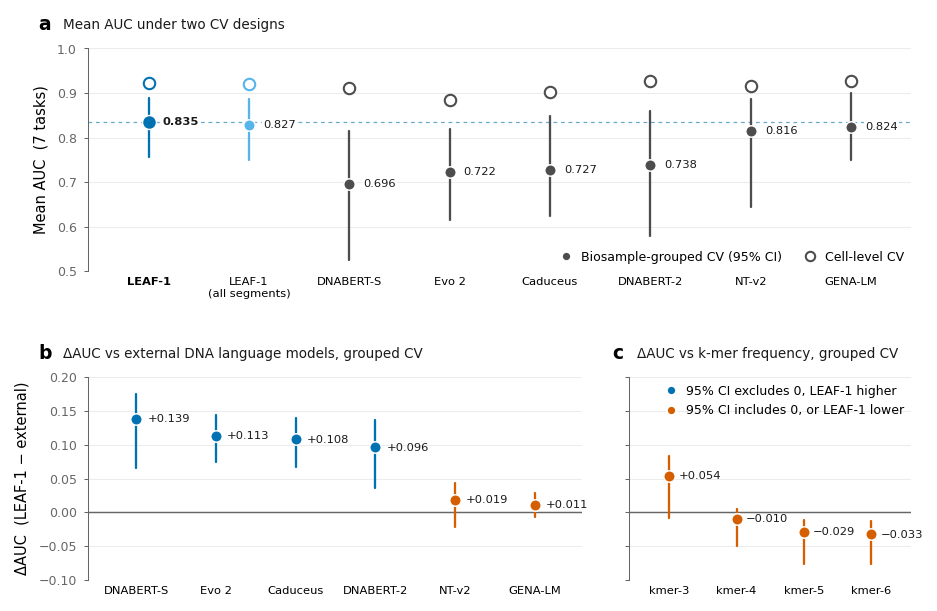

In [3]:
# ── Figure: mean AUC (a), ΔAUC against external DNA LMs (b) and k-mer (c) ──────
# Point estimates with 95% CI whiskers; per-task values are in the source table.
LEAF_BLUE, LEAF_ORNG, LEAF_SKY = OKABE_ITO["blue"], OKABE_ITO["orange"], OKABE_ITO["sky"]
INK, MUTED, GRID, COMP = "#1A1A1A", "#666666", "#ECECEC", "#4D4D4D"
WIDTH = 7.08   # in; 180 mm double column
DOT = 30


def bca_mean(vals, n_resamples=10_000, seed=42):
    """BCa 95% CI of the mean over tasks; same estimator and seed as Supp. Fig. 7a."""
    a = np.asarray(vals, dtype=float)
    r = sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples, confidence_level=0.95,
                           method="BCa", random_state=np.random.default_rng(seed))
    return float(np.mean(a)), float(r.confidence_interval.low), float(r.confidence_interval.high)


def style(ax, n):
    ax.set_xlim(-0.6, n - 0.4)
    ax.set_xticks(range(n))
    ax.tick_params(axis="x", length=0, pad=3, labelsize=5.5)
    ax.tick_params(axis="y", colors=MUTED, length=2, width=0.5)
    ax.spines["left"].set_color(MUTED)
    ax.spines["bottom"].set_visible(False)
    ax.grid(axis="y", color=GRID, lw=0.5, zorder=0)
    ax.set_axisbelow(True)


def model_colour(m):
    return LEAF_BLUE if m == "LEAF-1" else LEAF_SKY if m.startswith("LEAF-1") else COMP


def draw_abs(ax, order):
    """a: grouped-CV mean (filled, 95% CI) linked to the cell-level mean (open)."""
    rows = []
    for i, m in enumerate(order):
        mu, lo, hi = bca_mean(auc_g[m].values)
        cm = c.loc[m, "mean_auc"]
        rows.append(dict(model=m, ci_lo=lo, ci_hi=hi))
        col = model_colour(m)
        ax.plot([i, i], [lo, hi], color=col, lw=1.1, zorder=2, solid_capstyle="round")
        ax.scatter(i, cm, s=DOT, facecolor="white", edgecolor=col, linewidth=1.0, zorder=3)
        ax.scatter(i, mu, s=DOT * (1.5 if m == "LEAF-1" else 1), color=col,
                   edgecolor="white", linewidth=0.7, zorder=4)
        ax.text(i + 0.14, mu, f"{mu:.3f}", ha="left", va="center", fontsize=5.5,
                fontweight="bold" if m == "LEAF-1" else "normal", color=INK, zorder=5,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"))
    ax.axhline(auc_g["LEAF-1"].mean(), color=LEAF_BLUE, lw=0.6, ls=(0, (3, 3)), zorder=0, alpha=0.6)
    style(ax, len(order))
    ax.set_xticklabels([m.replace(" (all segments)", "\n(all segments)") for m in order])
    for lab in ax.get_xticklabels():
        if lab.get_text() == "LEAF-1":
            lab.set_fontweight("bold")
    ax.set_ylim(0.5, 1.0); ax.set_yticks(np.arange(0.5, 1.01, 0.1))
    ax.set_ylabel("Mean AUC  (7 tasks)")
    ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=4.5, mfc=COMP, mec="white",
                              label="Biosample-grouped CV (95% CI)"),
                       Line2D([], [], ls="", marker="o", ms=4.5, mfc="white", mec=COMP, mew=1.0,
                              label="Cell-level CV")],
              loc="lower right", ncol=2, frameon=False, handletextpad=0.2, columnspacing=1.2,
              borderaxespad=0.2)
    return pd.DataFrame(rows)


def draw_delta(ax, order, ylabel, ylim):
    """b, c: paired ΔAUC (LEAF-1 − model), grouped CV, with 95% CI."""
    s = g.loc[order]
    ax.axhline(0, color=MUTED, lw=0.7, zorder=1)
    for i, m in enumerate(order):
        d, lo, hi = s.loc[m, ["delta", "ci_lo", "ci_hi"]]
        col = LEAF_BLUE if lo > 0 else LEAF_ORNG
        ax.plot([i, i], [lo, hi], color=col, lw=1.1, zorder=2, solid_capstyle="round")
        ax.scatter(i, d, s=DOT, color=col, edgecolor="white", linewidth=0.7, zorder=3)
        ax.text(i + 0.14, d, f"{d:+.3f}".replace("-", "−"), ha="left", va="center", fontsize=5.5, color=INK)
    style(ax, len(order))
    ax.set_xticklabels(order)
    ax.set_ylim(*ylim)
    ax.set_yticks(np.round(np.arange(-0.10, ylim[1] + 1e-9, 0.05), 2))
    ax.set_ylabel(ylabel)


YLIM = (-0.10, 0.20)
assert g.loc[EXT_ORDER + KMER_ORDER, "ci_lo"].min() > YLIM[0] and g.loc[EXT_ORDER + KMER_ORDER, "ci_hi"].max() < YLIM[1]

fig = plt.figure(figsize=(WIDTH, 4.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1], width_ratios=[len(EXT_ORDER) + 1, len(KMER_ORDER)],
                      hspace=0.5, wspace=0.12)
axA = fig.add_subplot(gs[0, :]); axB = fig.add_subplot(gs[1, 0]); axC = fig.add_subplot(gs[1, 1], sharey=axB)
abs_rows = draw_abs(axA, A_ORDER)
draw_delta(axB, EXT_ORDER, "ΔAUC  (LEAF-1 − external)", YLIM)
draw_delta(axC, KMER_ORDER, "ΔAUC  (LEAF-1 − k-mer)", YLIM)
axC.tick_params(labelleft=False)
axC.set_ylabel("")
for ax, letter, title in ((axA, "a", "Mean AUC under two CV designs"),
                          (axB, "b", "ΔAUC vs external DNA language models, grouped CV"),
                          (axC, "c", "ΔAUC vs k-mer frequency, grouped CV")):
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(-24 if ax is not axC else -8, 7),
                textcoords="offset points", fontsize=9, fontweight="bold", va="bottom", ha="left")
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(-12 if ax is not axC else 4, 8),
                textcoords="offset points", fontsize=6.5, color=INK, va="bottom", ha="left")
axC.legend(handles=[Line2D([], [], ls="", marker="o", ms=4.5, mfc=LEAF_BLUE, mec="white",
                           label="95% CI excludes 0, LEAF-1 higher"),
                    Line2D([], [], ls="", marker="o", ms=4.5, mfc=LEAF_ORNG, mec="white",
                           label="95% CI includes 0, or LEAF-1 lower")],
           loc="upper right", frameon=False, handletextpad=0.2, borderaxespad=0.2)

table = (delta.merge(abs_rows[["model", "ci_lo", "ci_hi"]].rename(
             columns={"ci_lo": "mean_auc_ci_lo", "ci_hi": "mean_auc_ci_hi"}), on="model", how="left")
         .rename(columns={"ci_lo": "delta_ci_lo", "ci_hi": "delta_ci_hi"}))
table.loc[table["cv"] == "cell", ["mean_auc_ci_lo", "mean_auc_ci_hi"]] = np.nan
savefig(fig, OUT, "scatac_dnalm_delta_auc", data=table)
plt.show()

In [4]:
# ── Numbers for the figure legend and the response letter ─────────────────────
print(f"tasks in the mean: {', '.join(auc_g.index)}")
print(f"cell-level CV: every model between {c['mean_auc'].min():.3f} and {c['mean_auc'].max():.3f}")
for m in ["LEAF-1"] + [x for x in A_ORDER[1:]] + KMER_ORDER:
    r = g.loc[m]
    dd = "" if m == "LEAF-1" else (f"  ΔAUC {r.delta:+.3f} [{r.ci_lo:+.3f}, {r.ci_hi:+.3f}], "
                                   f"LEAF-1 higher in {int(r.tasks_leaf1_higher)}/7")
    print(f"{m:<22} grouped {r.mean_auc:.3f}  cell {c.loc[m, 'mean_auc']:.3f}{dd}")
lut = per_task[per_task["status"] == "excluded"].set_index("model")["auroc_grouped_cv"]
print("Luteal (excluded), grouped AUC:", ", ".join(f"{m} {v:.3f}" for m, v in lut.sort_values(ascending=False).items()))

tasks in the mean: Colon Epithelial Cell 1, Colonic Goblet Cell, Fibroblast (Epithelial), Mammary Epithelial, Smooth Muscle (Esophageal Muscularis) 3, Smooth Muscle (General Gastrointestinal), T lymphocyte 2 (CD4+)
cell-level CV: every model between 0.885 and 0.932
LEAF-1                 grouped 0.835  cell 0.922
LEAF-1 (all segments)  grouped 0.827  cell 0.920  ΔAUC +0.007 [-0.013, +0.015], LEAF-1 higher in 6/7
DNABERT-S              grouped 0.696  cell 0.912  ΔAUC +0.139 [+0.066, +0.176], LEAF-1 higher in 7/7
Evo 2                  grouped 0.722  cell 0.885  ΔAUC +0.113 [+0.074, +0.145], LEAF-1 higher in 7/7
Caduceus               grouped 0.727  cell 0.901  ΔAUC +0.108 [+0.067, +0.140], LEAF-1 higher in 6/7
DNABERT-2              grouped 0.738  cell 0.927  ΔAUC +0.096 [+0.036, +0.136], LEAF-1 higher in 5/7
NT-v2                  grouped 0.816  cell 0.915  ΔAUC +0.019 [-0.022, +0.043], LEAF-1 higher in 3/7
GENA-LM                grouped 0.824  cell 0.926  ΔAUC +0.011 [-0.008, +0.028],